# 07 — RNN vs LSTM: куда доходит градиент

Правило: перед каждой ячейкой с кодом — «Предсказание». Прогноз пишу **до** запуска, после запуска — одна строка «Что увидел».

In [8]:
import torch
import matplotlib.pyplot as plt
from rnn_lstm import *

B, T, D, H = 16, 60, 8, 32
torch.manual_seed(0)
xs = torch.randn(B, T, D)
h0 = torch.zeros(B, H); c0 = torch.zeros(B, H)
distance = torch.arange(T - 1, -1, -1)   # states[k] -> расстояние до последнего шага: T-1-k

## Эксперимент 1: обычная RNN

**Предсказание:** Loss = `hs[-1].sum()`, то есть только последний шаг. Строим норму $\lVert \partial L / \partial h_k \rVert$ от **расстояния** до последнего шага, ось Y логарифмическая.
1. Где норма будет больше: на расстоянии 1 или 50?
2. Какой формы будет кривая на лог-шкале и почему именно такой? (вспомни произведение множителей из вопроса 2)

_Мой прогноз:_
1. Больше на расстоянии 1 шаг от loss.
2. Чем дальше от loss, тем меньше градиент: на каждом шаге назад он умножается на очередной множитель, поэтому затухает экспоненциально. Если множитель примерно один и тот же (q), то после n шагов градиент ≈ qⁿ, и на лог-шкале кривая будет почти прямой (не идеально ровной), потому что log(qⁿ) зависит от n напрямую.

**Что увидел:** кривая на лог-шкале — почти прямая, наклонная вниз (не идеально ровная). Градиент затухает экспоненциально: на расстоянии 50 шагов норма около 1e-6, к самому дальнему шагу (59) — около 1e-7. Прогноз подтвердился.

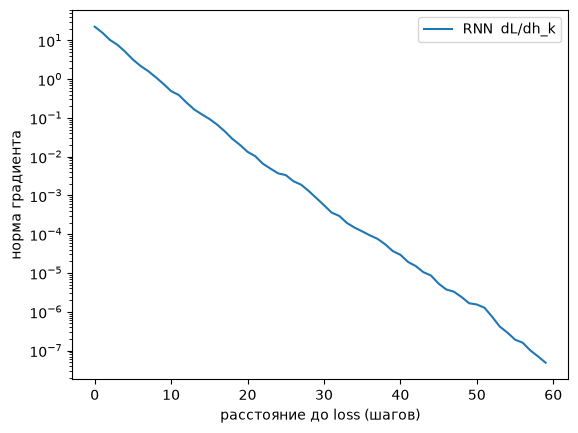

In [9]:
W_x, W_h, b = init_rnn(D, H, gain=1.0)
W_h.requires_grad_(True)
hs = rnn_forward(xs, h0, W_x, W_h, b)
rnn_norms = state_grad_norms(hs, hs[-1].sum())

plt.semilogy(distance, rnn_norms.detach(), label="RNN  dL/dh_k")
plt.xlabel("расстояние до loss (шагов)"); plt.ylabel("норма градиента"); plt.legend(); plt.show()

## Эксперимент 2: LSTM и forget bias

**Предсказание:** Теперь LSTM, смотрим градиент по **cell state** $c_k$. Две инициализации: `forget_bias=0` и `forget_bias=3`.
1. Чему примерно равен $f_t$ при bias 0, если остальная часть пре-активации около нуля? А при bias 3? (значения сигмоиды: $\sigma(0)=0.5$, $\sigma(3)\approx0.95$)
2. Какая из двух LSTM пронесёт градиент на 50 шагов, а какая затухнет почти как RNN?

_Мой прогноз:_
1. forget_bias прибавляется к пре-активации гейта f, поэтому f ≈ 0 при forget_bias=0 и f ≈ 3 при forget_bias=3.
2. Затухнет LSTM с forget_bias=0, а LSTM с forget_bias=3 пронесёт градиент на 50 шагов.

**Что увидел:** 
- LSTM с forget_bias=0 затухает **даже сильнее**, чем RNN: на расстоянии 50 норма ≈ 2e-8 (у RNN ≈ 1.5e-6).
- LSTM с forget_bias=3 не затухает вообще: норма ≈ 4–6 на расстояниях 5–30, а после 30–40 шагов начинает **расти** (≈ 17 на расстоянии 50, ≈ 39 на 59).

_Моя гипотеза:_ рост — накопительный эффект сигмоиды, которая при forget_bias=3 даёт f около единицы.

_Уточнение после разбора:_ одно f ≈ 0.95 дало бы медленное затухание (0.95⁵⁰ ≈ 0.08), а не рост. Градиент к c_k идёт двумя путями: напрямую по cell state (множитель f) и в обход, через h_k → гейты следующего шага → c_{k+1}. Суммарный множитель за шаг = f + вклад обходного пути; при f ≈ 0.95 он легко становится > 1, и градиент начинает взрываться. Это обратная сторона той же медали: затухание при множителе < 1, взрыв при > 1.

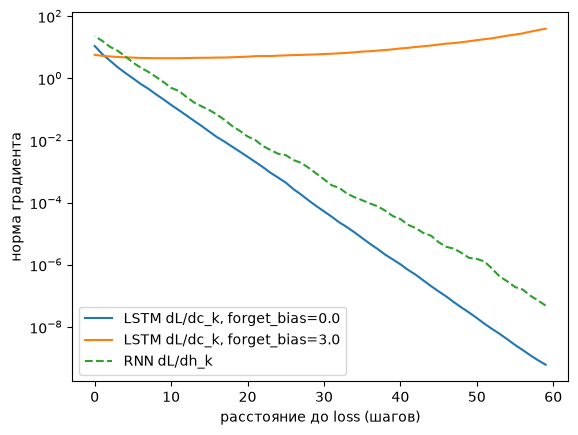

In [10]:
for fb in [0.0, 3.0]:
    W, b_l = init_lstm(D, H, forget_bias=fb)
    W.requires_grad_(True)
    hs_l, cs_l = lstm_forward(xs, h0, c0, W, b_l)
    norms = state_grad_norms(cs_l, hs_l[-1].sum())
    plt.semilogy(distance, norms.detach(), label=f"LSTM dL/dc_k, forget_bias={fb}")
plt.semilogy(distance, rnn_norms.detach(), "--", label="RNN dL/dh_k")
plt.xlabel("расстояние до loss (шагов)"); plt.ylabel("норма градиента"); plt.legend(); plt.show()

## Вывод своими словами
1. Почему LSTM с `forget_bias=0` в начале обучения тоже теряет далёкий градиент, хотя у неё есть cell state?
2. Что из этого следует для инициализации LSTM на практике?

_Мой ответ:_
1. Из-за сигмоиды: при forget_bias=0 и пре-активации около нуля f = σ(0) ≈ 0.5. Градиент по cell state на каждом шаге назад умножается на f, а по правилу степеней произведение множителей меньше единицы всегда затухает (0.5⁵⁰ ≈ 1e-15). Cell state — это «шоссе» для градиента, только если кран f открыт.
2. При инициализации LSTM forget bias нужно ставить положительным, чтобы f был близок к 1 и градиент не затухал, но и не взрывался: на практике берут около 1–2, плюс gradient clipping на случай взрыва.